# Notebook 6 - Outlier Treatment

In this notebook I learn what an outlier is, how it is different from an error, and how to detect it with the IQR, Z-score and percentile methods. Then I learn how to treat it: capping, flooring, winsorization, transformation, removing and retaining. The sprint rule for this topic is: 
do not automatically remove every outlier. For every outlier I must explain if it is an error or a valid extreme value, and what I do with it and why.

**Dataset:** Telco Customer Churn, after Notebooks 2 to 5. The numeric columns are `tenure`, `MonthlyCharges` and `TotalCharges`.

**Problem with this dataset:** The real Telco numeric columns have very few outliers (I check this in Section 2). So, as in the earlier notebooks, I make a demo copy `df_demo` where I inject two kinds of outliers that I know: *errors* (impossible values) and *valid extremes* (real premium customers). Then I can check if my methods and my decisions are right. The real data and the demo data are always clearly separated.

**Rule:** `df` (raw data) is never changed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")   # raw data, never modified

def fix_data_types(data):
    # Notebook 2
    out = data.copy()
    out["TotalCharges"] = pd.to_numeric(out["TotalCharges"], errors="coerce")
    out["SeniorCitizen"] = out["SeniorCitizen"].astype(bool)
    for col in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
        out[col] = out[col].map({"Yes": True, "No": False})
    for col in ["gender", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                "Contract", "PaymentMethod", "Churn"]:
        out[col] = out[col].astype("category")
    return out

def handle_missing_values(data):
    # Notebook 3
    out = data.copy()
    new_customer = out["tenure"] == 0
    out.loc[new_customer, "TotalCharges"] = out.loc[new_customer, "TotalCharges"].fillna(0.0)
    return out

def handle_duplicates(data, key="customerID", order_col="tenure"):
    # Notebook 4
    out = data.copy()
    audit = []
    out[key] = out[key].astype(str).str.strip().str.upper()
    exact = out.duplicated(keep="first")
    audit.append(out[exact].assign(reason="exact duplicate"))
    out = out[~exact]
    older = out.sort_values(order_col, kind="stable").duplicated(subset=key, keep="last").reindex(out.index)
    audit.append(out[older].assign(reason="older version of the same " + key))
    out = out[~older]
    return out, pd.concat(audit)

df_valid, _ = handle_duplicates(handle_missing_values(fix_data_types(df)))
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print("Shape:", df_valid.shape)

Shape: (7043, 21)


## 1. Problems from Sprint 4 Related to Outliers

| # | Problem | Why it exists | Planned fix |
|---|---|---|---|
| 1 | I noted "possible outliers" in the numeric columns, but did not decide anything | EDA only detects | detect with several methods and decide for each case |
| 2 | `TotalCharges` is right skewed | many new customers, few long-term ones | test a transformation (here and in Notebook 9) |
| 3 | Notebook 5 stops impossible values (range rules), but a value can be extreme and still possible | validation finds errors, not valid extremes | separate **error** from **valid extreme** |
| 4 | Scaling is affected by outliers | the mean and the standard deviation move | choose the scaler with the outliers in mind (Notebook 8) |

## 2. What is an Outlier?

**Concept:** An outlier is a value that is very different from most of the other values in the same column. It does not tell why it is different. It can be a mistake (a wrong number typed), or a real but rare case (a very rich customer). So the word "outlier" only means "unusual", and I must investigate it before I act.

**Examples:**
- Simple: in `[10, 12, 11, 13, 500]` the value 500 is an outlier.
- Real-world: a house price of 100 million in a list of normal houses.
- Business: one customer with a monthly bill that is three times higher than all others.
- AI/ML: one extreme value can pull the mean, the standard deviation and the regression line, and it can dominate the scaling.

**Implementation:** I look at the summary statistics and the boxplots of the three numeric columns of the real data, and I count the IQR outliers.

        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean     32.37           64.76       2279.73
std      24.56           30.09       2266.79
min       0.00           18.25          0.00
25%       9.00           35.50        398.55
50%      29.00           70.35       1394.55
75%      55.00           89.85       3786.60
max      72.00          118.75       8684.80

        column  lower bound  upper bound  IQR outliers  skewness
        tenure        -60.0        124.0             0      0.24
MonthlyCharges        -46.0        171.4             0     -0.22
  TotalCharges      -4683.5       8868.7             0      0.96


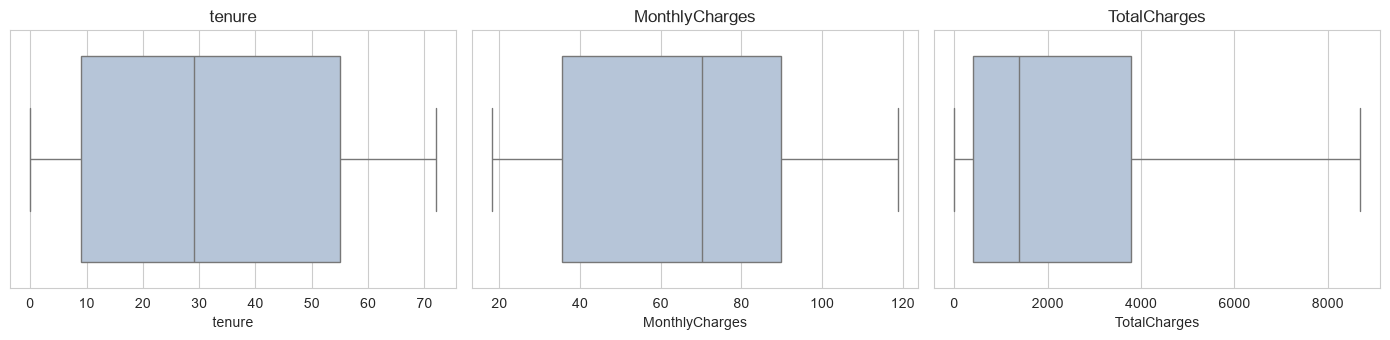

In [2]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

print(df_valid[num_cols].describe().round(2))

rows = []
for col in num_cols:
    lo, hi = iqr_bounds(df_valid[col])
    n_out = int(((df_valid[col] < lo) | (df_valid[col] > hi)).sum())
    rows.append((col, round(lo, 1), round(hi, 1), n_out, round(df_valid[col].skew(), 2)))
print()
print(pd.DataFrame(rows, columns=["column", "lower bound", "upper bound", "IQR outliers", "skewness"]).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df_valid[col], ax=ax, color="lightsteelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

**What the code does:**
- `iqr_bounds` calculates the first and third quartile (25% and 75% of the values), the IQR (the distance between them), and returns the two limits `Q1 - 1.5 x IQR` and `Q3 + 1.5 x IQR`.
- `describe()` shows count, mean, standard deviation, minimum, quartiles and maximum of each numeric column.
- The loop counts the values outside the IQR limits and the skewness of each column.
- The boxplot draws the same quartiles: the box is Q1 to Q3, the line inside is the median, the whiskers end at the limits, and the points outside are the outliers.

**Why this method was used:** Numbers and a picture together are the fastest way to see if a column has outliers. `describe()` already shows a warning sign: if the maximum is very far from the 75% quartile, there may be an outlier. The boxplot uses the same IQR rule as the count, so the picture and the number agree. I use the real data first, because I must know what is really in the dataset before I inject anything.

**Output meaning:** In the real data the IQR rule finds no outlier (or almost none) in `tenure` and `MonthlyCharges`, and also none in `TotalCharges`, although `TotalCharges` is clearly skewed (the median is lower than the mean, and the long tail goes to the right). Check the counts in your output.

**Insight obtained:** A skewed column is not the same as a column with outliers. The long tail of `TotalCharges` is made of normal long-term customers. This is a distribution problem (solved by transformation), and not an outlier problem.

**Effect on ML:** In the real Telco data there is nothing to remove. The outlier part of the preprocessing is mainly a protection for new data, and a learning exercise on how to decide.

In [3]:
# DEMO: a copy with outliers that I know. Two kinds: errors and valid extremes.
rng = np.random.default_rng(5)
df_demo = df_valid.copy()
used = set()

def pick(k, mask):
    candidates = [i for i in df_demo.index[mask] if i not in used]
    chosen = list(rng.choice(candidates, size=k, replace=False))
    used.update(chosen)
    return chosen

# ERRORS: a typing mistake (an extra digit) and a negative sign. TotalCharges stays as it was.
typo_idx = pick(3, (df_demo["MonthlyCharges"] > 60) & (df_demo["tenure"] > 12))
df_demo.loc[typo_idx, "MonthlyCharges"] = (df_demo.loc[typo_idx, "MonthlyCharges"] * 10).round(2)
neg_idx = pick(2, (df_demo["MonthlyCharges"] > 60) & (df_demo["tenure"] > 12))
df_demo.loc[neg_idx, "MonthlyCharges"] = -df_demo.loc[neg_idx, "MonthlyCharges"]

# VALID EXTREMES: premium customers with a long tenure. The total is consistent with the monthly charge.
valid_idx = pick(8, df_demo["tenure"] >= 48)
df_demo.loc[valid_idx, "MonthlyCharges"] = rng.uniform(180, 198, 8).round(2)
df_demo.loc[valid_idx, "TotalCharges"] = (df_demo.loc[valid_idx, "tenure"] * df_demo.loc[valid_idx, "MonthlyCharges"] * rng.uniform(0.95, 1.0, 8)).round(2)

error_idx = typo_idx + neg_idx
truth = pd.Series("normal", index=df_demo.index)
truth[error_idx] = "error"
truth[valid_idx] = "valid extreme"

print("Injected: errors =", len(error_idx), "| valid extremes =", len(valid_idx), "| rows in the demo copy:", len(df_demo))
print()
print(df_demo.loc[error_idx + valid_idx, ["tenure", "MonthlyCharges", "TotalCharges"]].assign(kind=truth[error_idx + valid_idx]).to_string())

Injected: errors = 5 | valid extremes = 8 | rows in the demo copy: 7043

      tenure  MonthlyCharges  TotalCharges           kind
5654      70         1053.50       7511.90          error
4712      50         1082.50       5431.40          error
161       20          824.00       1592.35          error
4430      32          -61.40       1864.65          error
3615      26         -105.75       2710.25          error
2693      72          187.83      13223.26  valid extreme
1973      72          197.54      13704.78  valid extreme
406       60          196.16      11698.78  valid extreme
2885      67          195.20      12466.47  valid extreme
4070      55          187.06      10123.27  valid extreme
909       71          188.87      13322.67  valid extreme
339       63          192.18      11639.58  valid extreme
6892      48          181.09       8646.88  valid extreme


**What the code does:**
- It copies the clean data into `df_demo`, and defines `pick`, which chooses random rows that are not used yet (so a row never gets two changes).
- **Errors:** for 3 customers it multiplies `MonthlyCharges` by 10 (a typing mistake like 99.9 becomes 999), and for 2 customers it changes the sign to negative. The `TotalCharges` is not changed, so it does not match the new monthly value.
- **Valid extremes:** for 8 customers with a tenure of at least 48 months it sets a very high monthly charge (180 to 198) and recalculates `TotalCharges` as tenure x monthly charge, so the two columns are consistent.
- It stores the truth in a column of labels (`error`, `valid extreme`, `normal`), and prints the changed rows.

**Why this method was used:** The only way to know if my detection and my decisions are correct is to know the answer. The two kinds of injected values are a copy of the two real situations: a mistake that no business can accept, and a rare customer that the business wants to keep. The valid extremes are consistent with the other columns on purpose, and the errors are not, because this is exactly the clue that a data scientist can use to separate them. The seed (`default_rng(5)`) makes the demo repeatable.

**Before:** 13 rows of the real data are normal customers.

**After:** The demo copy has 5 errors and 8 valid extremes, all in the numeric columns, and I know which row is which.

**Effect on ML:** I now have a test with known answers, to compare the detection methods and to test the treatment strategies in Section 12.

## 3. Outlier vs Error

**Concept:** After I find an unusual value, the first question is: **is it possible in the real world?** If it is impossible or it contradicts other columns, it is an **error**, and the correct action is to fix it (or set it as missing and impute it), not to treat it as an outlier. If it is possible and consistent, it is a **valid extreme observation**. It is real information, and removing it would remove real customers.

My checks to separate them:
1. **Range rule:** is the value outside the limits that are possible for the business? (the rule of Notebook 5)
2. **Consistency rule:** does it agree with other columns? (here: `TotalCharges` is about `tenure x MonthlyCharges`)
3. **Business knowledge:** is there a real reason for this value?

**Examples:**
- Simple: age 250 is an error, age 99 is an extreme but possible.
- Real-world: a body temperature of 52 degrees is a sensor error.
- Business: a monthly charge of 999 when the most expensive plan is 120 is an error. A charge of 190 for a premium bundle is a valid extreme.
- AI/ML: if errors are kept, they mislead the model. If valid extremes are removed, the model never learns about the high-value customers.

**Implementation:** I write the decision rule, and I check it against the known truth of the demo copy.

In [4]:
MIN_CHARGE, MAX_CHARGE = 1, 200          # business range of a monthly charge (Notebook 5)

def explain_value(row):
    # returns (kind, reason) for a row with an unusual MonthlyCharges or TotalCharges
    monthly, total, tenure = row["MonthlyCharges"], row["TotalCharges"], row["tenure"]
    if monthly < MIN_CHARGE or monthly > MAX_CHARGE:
        return "error", "monthly charge " + str(round(monthly, 1)) + " is outside the possible range [" + str(MIN_CHARGE) + ", " + str(MAX_CHARGE) + "]"
    ratio = total / (tenure * monthly) if tenure * monthly > 0 else np.nan
    if ratio == ratio and not (0.5 <= ratio <= 1.5):
        return "error", "total charges do not match tenure x monthly charge (ratio " + str(round(ratio, 2)) + ")"
    return "valid extreme", "inside the possible range and consistent with tenure and total charges"

injected_rows = df_demo.loc[error_idx + valid_idx]
decisions = injected_rows.apply(explain_value, axis=1, result_type="expand")
decisions.columns = ["decided", "reason"]
decisions["truth"] = truth[decisions.index]

print("Rows decided correctly:", int((decisions["decided"] == decisions["truth"]).sum()), "of", len(decisions))
print()
print(decisions.assign(MonthlyCharges=injected_rows["MonthlyCharges"])[["MonthlyCharges", "decided", "truth", "reason"]].to_string())

Rows decided correctly: 13 of 13

      MonthlyCharges        decided          truth                                                                  reason
5654         1053.50          error          error            monthly charge 1053.5 is outside the possible range [1, 200]
4712         1082.50          error          error            monthly charge 1082.5 is outside the possible range [1, 200]
161           824.00          error          error             monthly charge 824.0 is outside the possible range [1, 200]
4430          -61.40          error          error             monthly charge -61.4 is outside the possible range [1, 200]
3615         -105.75          error          error            monthly charge -105.8 is outside the possible range [1, 200]
2693          187.83  valid extreme  valid extreme  inside the possible range and consistent with tenure and total charges
1973          197.54  valid extreme  valid extreme  inside the possible range and consistent with tenure 

**What the code does:**
- The function `explain_value` takes one row and applies the checks in order. First the range rule: a monthly charge below 1 or above 200 is an error. If the value is inside the range, it calculates the ratio `TotalCharges / (tenure x MonthlyCharges)`: a ratio outside 0.5 to 1.5 means that the total does not match the monthly charge, so it is an error. If both checks pass, it is a valid extreme.
- It returns the decision and a short sentence with the reason.
- It is applied to the 13 injected rows, and compared with the truth.

**Why this method was used:** The order of the checks matters. The range check is the cheapest and the most certain. The consistency check is needed because a typing mistake like 10 times the value can still be inside the allowed range (a monthly charge of 180 that should be 18). Using two columns that must agree is the strongest clue to separate an error from a real value. A function that also returns the **reason** makes each decision explainable, which is a requirement of the sprint.

**Output meaning:** All 13 rows are decided correctly. The negative values and the values far outside the range are errors because of the range rule. The multiplied values are errors because the total does not match. The 8 premium customers are valid extremes because they are in the range and consistent.

**Effect on ML:** The error must be corrected and not just treated as an outlier. The valid extreme must be kept as information, and the only question is how to help the model with it (capping, transformation, or a robust model).

## 4. IQR Method

**Concept:** The IQR (interquartile range) method uses the middle 50% of the data. A value is an outlier if it is below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`. The factor 1.5 is the usual choice, and 3 is used for "extreme" outliers.

- **When to use:** numeric data, any shape of distribution, and when there are already some outliers (the quartiles do not move much).
- **When not to use:** very skewed data (the long tail is flagged although it is normal), very small data, or data that is not numeric.
- **Advantages:** robust (based on quartiles), no assumption about the distribution, and a simple picture (the boxplot).
- **Limitations:** the factor 1.5 is a convention and not a law, it flags many points in skewed columns, and it works one column at a time.

**Examples:**
- Simple: in `[10, 12, 11, 13, 500]` the limits are about 8 and 16, so 500 is flagged.
- Real-world: the whiskers of a boxplot.
- Business: finding unusual monthly bills for a review.
- AI/ML: a standard first check before scaling.

**Implementation:** I apply the method to the demo copy, check how many of the 13 injected rows it finds, and then I explain every flagged value.

        column  real data  demo copy  injected found  not injected
        tenure          0          0               0             0
MonthlyCharges          0         13              13             0
  TotalCharges          0          7               7             0

Injected rows found by IQR in at least one column: 13 of 13


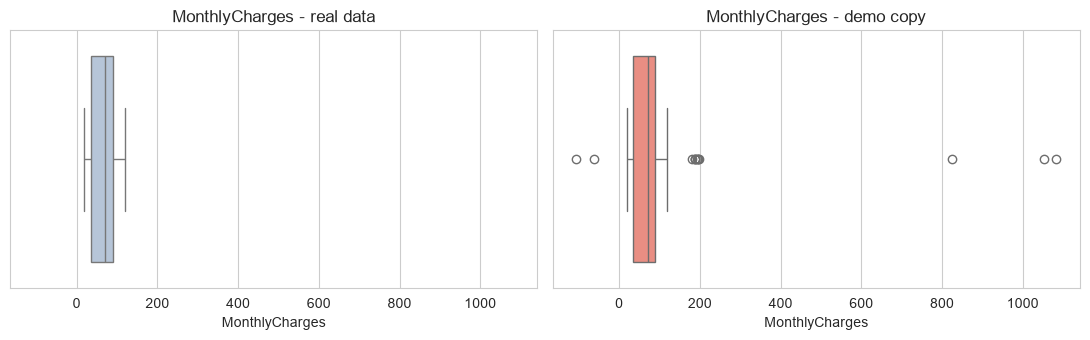

In [5]:
def flag_iqr(s, k=1.5):
    lo, hi = iqr_bounds(s, k)
    return (s < lo) | (s > hi)

injected_all = set(error_idx + valid_idx)
rows = []
for col in num_cols:
    flagged_real = flag_iqr(df_valid[col])
    flagged_demo = flag_iqr(df_demo[col])
    found = len(set(df_demo.index[flagged_demo]) & injected_all)
    false_alarms = int(flagged_demo.sum()) - found
    rows.append((col, int(flagged_real.sum()), int(flagged_demo.sum()), found, false_alarms))
print(pd.DataFrame(rows, columns=["column", "real data", "demo copy", "injected found", "not injected"]).to_string(index=False))

flag_any = pd.concat([flag_iqr(df_demo[c]) for c in num_cols], axis=1).any(axis=1)
print("\nInjected rows found by IQR in at least one column:", len(set(df_demo.index[flag_any]) & injected_all), "of", len(injected_all))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
sns.boxplot(x=df_valid["MonthlyCharges"], ax=axes[0], color="lightsteelblue"); axes[0].set_title("MonthlyCharges - real data")
sns.boxplot(x=df_demo["MonthlyCharges"], ax=axes[1], color="salmon");           axes[1].set_title("MonthlyCharges - demo copy")
plt.tight_layout()
plt.show()

In [6]:
# the decision table: for EVERY flagged value, what is it and what do I do?
flagged_rows = df_demo[flag_any]
table = flagged_rows[num_cols].copy()
table[["kind", "reason"]] = flagged_rows.apply(explain_value, axis=1, result_type="expand")

def action(kind):
    if kind == "error":
        return pd.Series({"remove row?": "no", "cap?": "no", "transform?": "no",
                          "action": "set the value to missing and impute it (Notebook 3 methods)",
                          "why": "the customer is real, only the value is wrong, so the row is kept"})
    return pd.Series({"remove row?": "no", "cap?": "only for scale-sensitive models", "transform?": "if skew matters",
                      "action": "keep the value; use a robust scaler / tree model, or cap inside the pipeline",
                      "why": "real premium customer, removing it loses true information"})

table = table.join(table["kind"].apply(action))
print(table.drop(columns=["reason"]).head(14).to_string())

      tenure  MonthlyCharges  TotalCharges           kind remove row?                             cap?       transform?                                                                        action                                                                why
161       20          824.00       1592.35          error          no                               no               no                   set the value to missing and impute it (Notebook 3 methods)  the customer is real, only the value is wrong, so the row is kept
339       63          192.18      11639.58  valid extreme          no  only for scale-sensitive models  if skew matters  keep the value; use a robust scaler / tree model, or cap inside the pipeline          real premium customer, removing it loses true information
406       60          196.16      11698.78  valid extreme          no  only for scale-sensitive models  if skew matters  keep the value; use a robust scaler / tree model, or cap inside the pipeline        

**What the code does:**
- `flag_iqr` returns True for the values outside the IQR limits.
- For each numeric column it counts the flagged values on the real data and on the demo copy, how many of the flagged values are injected rows, and how many are flagged although I did not inject them.
- It draws the boxplot of `MonthlyCharges` for the real data and for the demo copy, with the same axis, to see the effect of the injected values.
- The second cell takes all the flagged rows, uses `explain_value` to decide whether each one is an error or a valid extreme, and adds the decision columns: remove, cap, transform, action and why.

**Why this method was used:** The IQR rule is the standard first method, because it does not depend on the mean and the standard deviation, which the outliers themselves can change. I count the "not injected" flags, because a method that flags many normal values is not useful, even if it finds all the outliers. The decision table is the direct answer to the sprint requirement: for every detected outlier it says if it is an error, if it should be removed, capped or transformed, and **why**. I never choose "remove row" here, because in both cases the customer is real: for an error the value is wrong, for a valid extreme the value is true.

**Output meaning:** On the real data the count is 0 in every column. On the demo copy the IQR rule finds the injected values (the high and the negative `MonthlyCharges`, and the large `TotalCharges` of the premium customers) with no or almost no extra flags. The boxplot shows the real data as a compact box with no points outside, and the demo copy with points far to the left and to the right. In the decision table the errors get the action "set to missing and impute", and the valid extremes get "keep".

**Effect on ML:** The IQR method detects the unusual values, and the decision comes from business logic. The same detected number of 13 rows needs two different actions.

## 5. Z-Score Method

**Concept:** The z-score says how many standard deviations a value is from the mean: `z = (x - mean) / std`. A value with `|z| > 3` is usually called an outlier. A more robust version, the **modified z-score**, uses the median and the MAD (median absolute deviation) instead of the mean and the standard deviation: `0.6745 x (x - median) / MAD`, with the limit 3.5.

- **When to use:** data that is roughly normal (bell shaped), and a small number of outliers.
- **When not to use:** skewed data, many outliers, or small samples (the outliers change the mean and the standard deviation, and hide themselves).
- **Advantages:** simple, the unit is the standard deviation, it is easy to explain.
- **Limitations:** the mean and the standard deviation are themselves moved by the outliers (the "masking" effect), and it assumes a normal distribution.

**Examples:**
- Simple: a value 4 standard deviations above the mean is very rare in a normal distribution.
- Real-world: an exam score far from the class average.
- Business: a sales figure that is very far from the usual level.
- AI/ML: standardisation uses the same formula, so extreme z-scores show which points will be large after scaling.

**Implementation:**

In [7]:
def flag_z(s, threshold=3):
    z = (s - s.mean()) / s.std()
    return z.abs() > threshold

def flag_modified_z(s, threshold=3.5):
    median = s.median()
    mad = (s - median).abs().median()
    mz = 0.6745 * (s - median) / mad
    return mz.abs() > threshold

col = "MonthlyCharges"
print("Mean and standard deviation of", col)
print("  real data :", round(df_valid[col].mean(), 1), "/", round(df_valid[col].std(), 1))
print("  demo copy :", round(df_demo[col].mean(), 1), "/", round(df_demo[col].std(), 1), "(moved by the outliers)")

rows = []
for c in num_cols:
    for name, func in [("IQR (1.5)", flag_iqr), ("z-score (3)", flag_z), ("modified z (3.5)", flag_modified_z)]:
        flagged = func(df_demo[c])
        found = len(set(df_demo.index[flagged]) & injected_all)
        rows.append((c, name, int(func(df_valid[c]).sum()), int(flagged.sum()), found))
pd.DataFrame(rows, columns=["column", "method", "real data", "demo copy", "injected found"]).pivot(index="column", columns="method", values=["real data", "demo copy", "injected found"])

Mean and standard deviation of MonthlyCharges
  real data : 64.8 / 30.1
  demo copy : 65.2 / 36.0 (moved by the outliers)


real data                              demo copy  \
method         IQR (1.5) modified z (3.5) z-score (3) IQR (1.5)   
column                                                            
MonthlyCharges         0                0           0        13   
TotalCharges           0              136           0         7   
tenure                 0                0           0         0   

                                            injected found                   \
method         modified z (3.5) z-score (3)      IQR (1.5) modified z (3.5)   
column                                                                        
MonthlyCharges                7          13             13                7   
TotalCharges                142           7              7                8   
tenure                        0           0              0                0   

                            
method         z-score (3)  
column                      
MonthlyCharges          13  
TotalCharges             7  
tenure                   0

**What the code does:**
- `flag_z` standardises the column with the mean and the standard deviation, and flags `|z| > 3`.
- `flag_modified_z` uses the median and the MAD, and flags a modified z-score above 3.5.
- It first prints the mean and the standard deviation of `MonthlyCharges` in the real data and in the demo copy, to show how the injected values move them.
- Then it runs the IQR, z-score and modified z-score methods on the three columns, and puts in one table the number of flagged values in the real data, in the demo copy and how many injected rows each method found.

**Why this method was used:** I put the three methods side by side because they are based on different statistics (quartiles, mean and standard deviation, median and MAD), and I want to see where they agree. The first print explains the main weakness of the z-score: when outliers exist, the standard deviation becomes larger, so the z-score of every outlier becomes smaller, and some of them can escape. The modified z-score is built to avoid this, since the median and the MAD hardly move.

**Output meaning:** The standard deviation of `MonthlyCharges` is larger in the demo copy than in the real data. On the real data, none of the three methods flags anything. On the demo copy the three methods find most of the injected rows. The three methods do not give the same result: for `MonthlyCharges` the modified z-score flagged fewer of the injected rows than the other two (in my test run it found only the clearest ones). The reason is that `MonthlyCharges` is spread over a wide range, so the MAD is large and the limit of 3.5 is far from the median. This shows that the thresholds 1.5, 3 and 3.5 are conventions and not laws. For the skewed `TotalCharges` the methods also disagree, because they treat the long right tail differently.

**Effect on ML:** The choice of method changes which rows are flagged. If the data is roughly normal and has a few outliers, the z-score is enough. For skewed data and for data with many outliers the IQR or the modified z-score are the safer choice.

## 6. Percentile Method

**Concept:** The percentile method flags the values below a low percentile (for example the 1st) or above a high percentile (for example the 99th). It does not use the shape of the data.

- **When to use:** when I want to limit the influence of the extremes of a large dataset (as the base of winsorization), or when a business rule says "the top 1%".
- **When not to use:** as a detector of errors, because it **always flags a fixed share of the rows**, even when the data is perfectly clean.
- **Advantages:** simple, no assumption, and I choose the share directly.
- **Limitations:** a clean column still gets 2% of its rows flagged, and the method cannot tell an error from a normal value.

**Examples:**
- Simple: the highest 1% of salaries.
- Real-world: the top 5% of a test score.
- Business: the 1% of customers with the highest bills.
- AI/ML: a quick way to reduce the effect of the tails before scaling.

**Implementation:**

In [8]:
def flag_percentile(s, low=0.01, high=0.99):
    lo, hi = s.quantile([low, high])
    return (s < lo) | (s > hi)

rows = []
for c in num_cols:
    real = flag_percentile(df_valid[c])
    demo = flag_percentile(df_demo[c])
    found = len(set(df_demo.index[demo]) & injected_all)
    rows.append((c, int(real.sum()), round(real.mean() * 100, 1), int(demo.sum()), found, int(demo.sum()) - found))
print(pd.DataFrame(rows, columns=["column", "real data flagged", "real data %", "demo flagged", "injected found", "not injected"]).to_string(index=False))

        column  real data flagged  real data %  demo flagged  injected found  not injected
        tenure                 11          0.2            11               0            11
MonthlyCharges                136          1.9           137              13           124
  TotalCharges                136          1.9           136               8           128


**What the code does:** `flag_percentile` finds the 1st and the 99th percentile of the column, and flags every value outside them. The code counts the flagged values in the real data and in the demo copy, calculates the share in the real data, and counts how many injected rows were found and how many flagged rows were not injected.

**Why this method was used:** I use it to show its main weakness with numbers. By definition, the method flags about 2% of the rows in **any** column, including a clean one.

**Output meaning:** On the real data, which has no outliers by the IQR rule, the method still flags about 2% of the rows in `MonthlyCharges` and `TotalCharges` (around 140 rows each). For `tenure`, which has many repeated values, it flags fewer. On the demo copy it finds the injected rows, but it also flags more than a hundred normal customers.

**Insight obtained:** Flagging is not the same as finding an outlier. The percentile method is a good tool for **capping** (Section 7), where the aim is to reduce the influence of the tails, but it is a poor tool for **detection**.

**Effect on ML:** If I removed the flagged rows, I would remove about 2% of the customers, who are normal. That is the reason why the percentile method must never be the only evidence for removing data.

## 7. Capping, Flooring and Winsorization

**Concept:** These methods keep the row but limit the value.
- **Capping:** values above an upper limit are replaced by the limit.
- **Flooring:** values below a lower limit are replaced by the limit.
- **Winsorization:** capping and flooring together, with the limits taken from percentiles (for example the 1st and the 99th percentile).

The limits can come from the IQR rule, from percentiles, or from a business rule.

- **When to use:** the value is real or probably real, but I want to reduce its influence on a scale-sensitive model (linear models, KNN, SVM, neural networks).
- **When not to use:** the value is an error (fix it instead), the extreme itself is the information that the model needs, or the model is a tree (trees are not affected by the size of an extreme value).
- **Advantages:** no row is lost, the result is easy to explain, and it reduces the effect on the mean, the standard deviation and the scaling.
- **Limitations:** the real value is changed (information about "how extreme" is lost), many rows can be cut if the limits are tight, and the limits are learned from data, so they must be learned from the **training data only**.

**Examples:**
- Simple: a salary of 1,000,000 in a list of normal salaries is replaced by 200,000.
- Real-world: a thermometer is limited to its maximum.
- Business: very high bills are limited at the 99th percentile for a pricing model.
- AI/ML: scikit-learn pipelines can learn the limits in `fit` and apply them in `transform`.

**Implementation:** First I fix the errors of the demo copy (they are not outliers to cap, they are wrong values). Then I treat the valid extremes with the three methods and compare.

In [9]:
# step 1: fix the errors (set to missing, then fill with the median of the same InternetService group)
def fix_errors(data):
    out = data.copy()
    wrong = out.apply(lambda r: explain_value(r)[0] == "error" if (r["MonthlyCharges"] < MIN_CHARGE or r["MonthlyCharges"] > MAX_CHARGE
                      or (r["tenure"] * r["MonthlyCharges"] > 0 and not 0.5 <= r["TotalCharges"] / (r["tenure"] * r["MonthlyCharges"]) <= 1.5)) else False, axis=1)
    out.loc[wrong, "MonthlyCharges"] = np.nan
    out["MonthlyCharges"] = out["MonthlyCharges"].fillna(out.groupby("InternetService", observed=True)["MonthlyCharges"].transform("median"))
    return out, int(wrong.sum())

df_fixed, n_fixed = fix_errors(df_demo)
print("Errors fixed:", n_fixed, "| missing left:", int(df_fixed["MonthlyCharges"].isna().sum()))

# step 2: limits for the valid extremes
s = df_fixed["MonthlyCharges"]
iqr_lo, iqr_hi = iqr_bounds(s)
p_lo, p_hi = s.quantile([0.01, 0.99])
print("IQR limits:", round(iqr_lo, 1), "to", round(iqr_hi, 1), "| percentile limits (1%, 99%):", round(p_lo, 1), "to", round(p_hi, 1))

versions = {
    "demo copy (errors in)": df_demo["MonthlyCharges"],
    "errors fixed, extremes kept": s,
    "capped at IQR upper limit": s.clip(upper=iqr_hi),
    "winsorized 1% / 99%": s.clip(lower=p_lo, upper=p_hi),
}
rows = []
for name, v in versions.items():
    rows.append((name, round(v.min(), 1), round(v.max(), 1), round(v.mean(), 2), round(v.std(), 2), round(v.skew(), 2),
                 int((v != df_fixed["MonthlyCharges"]).sum()) if name != "demo copy (errors in)" else int((v != df_valid["MonthlyCharges"]).sum())))
print()
print(pd.DataFrame(rows, columns=["version", "min", "max", "mean", "std", "skew", "rows changed"]).to_string(index=False))
print("\nReference, real data: mean", round(df_valid["MonthlyCharges"].mean(), 2), "| std", round(df_valid["MonthlyCharges"].std(), 2), "| skew", round(df_valid["MonthlyCharges"].skew(), 2))

# a small example of the three words (DEMO salaries)
salary = pd.Series([-5000, 100, 40000, 52000, 61000, 1_000_000])
print("\nSalary demo      :", salary.tolist())
print("floor at 0       :", salary.clip(lower=0).tolist())
print("cap at 200000    :", salary.clip(upper=200000).tolist())
print("floor + cap      :", salary.clip(lower=0, upper=200000).tolist())

Errors fixed: 7 | missing left: 0
IQR limits: -46.0 to 171.5 | percentile limits (1%, 99%): 19.2 to 115.0

                    version    min    max  mean   std  skew  rows changed
      demo copy (errors in) -105.8 1082.5 65.21 35.99  7.35            13
errors fixed, extremes kept   18.2  197.5 64.87 30.36 -0.15             0
  capped at IQR upper limit   18.2  171.5 64.85 30.27 -0.18             8
        winsorized 1% / 99%   19.2  115.0 64.78 30.08 -0.22           136

Reference, real data: mean 64.76 | std 30.09 | skew -0.22

Salary demo      : [-5000, 100, 40000, 52000, 61000, 1000000]
floor at 0       : [0, 100, 40000, 52000, 61000, 1000000]
cap at 200000    : [-5000, 100, 40000, 52000, 61000, 200000]
floor + cap      : [0, 100, 40000, 52000, 61000, 200000]


**What the code does:**
- `fix_errors` finds the rows that my decision rule calls an error, sets their `MonthlyCharges` to missing, and fills them with the median of the same `InternetService` group (the group-based imputation of Notebook 3).
- It calculates two kinds of limits on the fixed column: the IQR limits and the 1st and 99th percentiles.
- `clip(upper=...)` is capping, `clip(lower=...)` is flooring and `clip(lower=..., upper=...)` is winsorization.
- It prints a table with the minimum, maximum, mean, standard deviation, skewness and number of changed rows for each version, and the real data as a reference.
- The salary example shows the three words on a small list: the negative salary is floored to 0, the huge salary is capped to 200,000.

**Why this method was used:** Errors are fixed first, because capping an error would hide a wrong value inside the data, and the result would look correct although it is not. Group-based imputation is used for the errors, because a median of the same internet service group is closer to the true price than the global mean. `clip` is the simplest way to cap and floor in pandas, and it keeps the index and the number of rows. I show the IQR limits and the percentile limits together because the first one adapts to the data, and the second one changes a fixed share of the rows.

**Output meaning:** After fixing the errors, the mean and standard deviation are back close to the real data. The IQR cap changes only the few valid extremes. The 1%/99% winsorization changes more rows (about 2% of the data), because the percentiles always cut a fixed share, including normal customers. The maximum value falls in both capped versions.

**Important:** The limits (`iqr_hi`, `p_lo`, `p_hi`) are learned from the data. In a real project they must be calculated from the training set and applied to validation and test sets. I show how in Section 12 with a transformer that learns the limits in `fit`.

**Effect on ML:** Capping reduces the pull of the extreme values on a linear model, with no loss of rows, but the model no longer knows how extreme the customer was. For a tree model it changes nothing important.

## 8. Transformation

**Concept:** A transformation changes the scale of a column with a mathematical function, for example the logarithm or the square root. It pulls a long right tail towards the middle, so values that were far away become closer, and no value is removed or limited. It is the best way to handle **skew**, and a valid extreme becomes much less extreme.

- **When to use:** positive, right skewed data (money, counts, durations), where the extremes are valid.
- **When not to use:** data with negative values (the log needs positive values), data that is already symmetric, or when the original unit must be kept for the explanation.
- **Advantages:** no rows lost, no limits to learn, and the whole shape is improved.
- **Limitations:** the result is on a new scale that is harder to explain, a strong transformation can over-correct (the skew becomes negative), and zero needs `log1p`.

**Examples:**
- Simple: the logarithm of 10, 100 and 1000 is 1, 2 and 3.
- Real-world: earthquake size is measured on a log scale.
- Business: the logarithm of the revenue per customer.
- AI/ML: linear models work better when the features are not strongly skewed. The full list (power, Box-Cox, Yeo-Johnson) is in Notebook 9.

**Implementation:** I use the real `TotalCharges`, which is naturally right skewed (and has zeros, so I use `log1p`, which is `log(1 + x)`), and I compare the square root and the logarithm.

    version  skewness  IQR outliers  min     max
   original      0.96             0  0.0 8684.80
square root      0.31             0  0.0   93.19
      log1p     -0.82            11  0.0    9.07


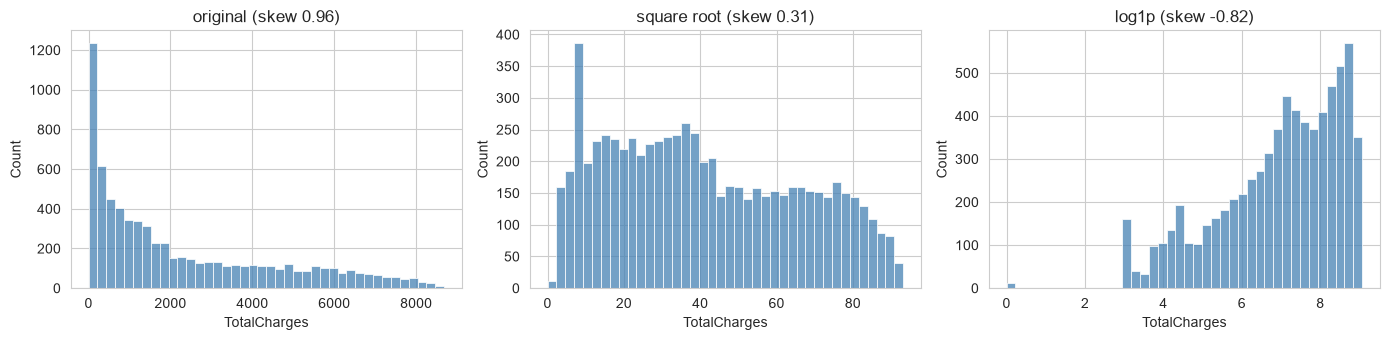


TotalCharges of the premium customers: original max 13705 | after log1p 9.53 | typical customer (median) after log1p: 7.24


In [10]:
s = df_valid["TotalCharges"]
versions = {"original": s, "square root": np.sqrt(s), "log1p": np.log1p(s)}

rows = []
for name, v in versions.items():
    rows.append((name, round(v.skew(), 2), int(flag_iqr(v).sum()), round(v.min(), 2), round(v.max(), 2)))
print(pd.DataFrame(rows, columns=["version", "skewness", "IQR outliers", "min", "max"]).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (name, v) in zip(axes, versions.items()):
    sns.histplot(v, bins=40, ax=ax, color="steelblue")
    ax.set_title(name + " (skew " + str(round(v.skew(), 2)) + ")")
plt.tight_layout()
plt.show()

# a valid extreme in the demo copy, before and after the log
extreme = df_demo.loc[valid_idx, "TotalCharges"]
print("\nTotalCharges of the premium customers: original max", round(extreme.max()), "| after log1p", round(np.log1p(extreme).max(), 2),
      "| typical customer (median) after log1p:", round(np.log1p(df_valid['TotalCharges']).median(), 2))

**What the code does:**
- It applies the square root and `log1p` to the real `TotalCharges`, and for each version prints the skewness, the number of IQR outliers, and the minimum and maximum.
- It draws the three histograms side by side.
- It takes the `TotalCharges` of the 8 premium customers in the demo copy, and shows their largest value before and after `log1p`, next to the typical value.

**Why this method was used:** I use `log1p` instead of `log`, because `TotalCharges` has zeros (the new customers of Notebook 3), and `log(0)` is not defined. I compare two transformations because they have different strength: the square root is mild, and the logarithm is strong. The skewness is the number that measures the improvement, and the histogram shows the shape. The last print shows the effect on a valid extreme: its value stays in the data, but it is much closer to the other customers.

**Output meaning:** The original `TotalCharges` has a clear positive skew. The square root reduces it a lot and does not create outliers. The logarithm reduces it too much: the skew becomes negative (a tail to the left), and the small totals of the new customers now look like outliers on the left side, so the IQR rule flags many rows. This is an over-correction. The premium customers after the logarithm are only a little above the typical value.

**Insight obtained:** A transformation does not delete the extreme customers. It keeps them and makes them less dominant, but a transformation that is too strong creates new outliers on the other side. The right strength depends on the data, and the best choice is tested in Notebook 9, where Box-Cox and Yeo-Johnson select the strength automatically.

**Effect on ML:** Linear models and distance-based models get a more balanced feature. A transformation is a learned or fixed step in the pipeline, and the same function must be applied to the validation and test data.

## 9. Removing Outliers

**Concept:** Removing an outlier means deleting the row. It is the strongest action, and it cannot be undone without the original data.

- **When to use:** the row is an **error that cannot be fixed**, the row is clearly not from the population that I want to model (a test account, a company that is not a customer), or the number of such rows is tiny and I have a documented reason.
- **When not to use:** the value is a valid extreme, the outlier is the most interesting case (fraud, churn of a big customer), or I remove it only because the method flagged it.
- **Advantages:** simple, and it can clean a column that is damaged by a few impossible values.
- **Limitations:** I lose real information and real customers, I can create a bias (for example I remove all the high-value customers), and the number of rows decreases.

**Examples:**
- Simple: remove a row with age 250 when the true age is unknown.
- Real-world: remove the test records of the developers from the customer table.
- Business: a rare, big customer must not be removed from a revenue model.
- AI/ML: if all the extreme customers are removed, the model has never seen them, and it will be wrong for them in production.

**Implementation:** I remove every row that the IQR rule flags in the demo copy, and I look at who is lost.

In [11]:
removed = df_demo[flag_any]
kept = df_demo[~flag_any]

print("Rows before:", len(df_demo), "| removed by the IQR rule:", len(removed), "| after:", len(kept))
print("Of the removed rows:", truth[removed.index].value_counts().to_dict())

valid_removed = df_demo.loc[[i for i in removed.index if truth[i] == "valid extreme"]]
print("\nThe valid premium customers that would be lost:")
print("  mean tenure     :", round(valid_removed["tenure"].mean(), 1), "months (all customers:", round(df_demo["tenure"].mean(), 1), ")")
print("  mean MonthlyChg :", round(valid_removed["MonthlyCharges"].mean(), 1), "(all customers:", round(df_demo["MonthlyCharges"].mean(), 1), ")")
print("  churn rate      :", round((valid_removed["Churn"] == "Yes").mean() * 100, 1), "% (all customers:", round((df_demo["Churn"] == "Yes").mean() * 100, 1), "%)")
print("  highest MonthlyCharges left in the data:", round(kept["MonthlyCharges"].max(), 1))

Rows before: 7043 | removed by the IQR rule: 13 | after: 7030
Of the removed rows: {'valid extreme': 8, 'error': 5}

The valid premium customers that would be lost:
  mean tenure     : 63.5 months (all customers: 32.4 )
  mean MonthlyChg : 190.7 (all customers: 65.2 )
  churn rate      : 12.5 % (all customers: 26.5 %)
  highest MonthlyCharges left in the data: 118.8


**What the code does:**
- It splits the demo copy into the rows that the IQR rule flagged (`removed`) and the rest (`kept`), and counts how many rows are removed and of which truth kind.
- For the valid extremes that would be lost, it prints their mean tenure, mean monthly charge and churn rate, and compares them with all customers.
- It prints the highest monthly charge that is still in the data after the removal.

**Why this method was used:** I use the ground truth of the demo to show the real cost of an automatic removal. The comparison with all customers answers the important question: **who** is lost, not only how many.

**Output meaning:** The removal deletes the 5 errors, but also the 8 premium customers, who are valid. These are customers with a long tenure and a high monthly charge, so the data no longer contains any customer with a high price. The maximum monthly charge left in the data is now the maximum of the normal plans.

**Insight obtained:** An automatic removal does two things at once: it removes the mistakes (good) and it removes the best customers (bad). The 5 errors should have been fixed, and the 8 valid extremes should have been kept.

**Effect on ML:** A model trained on the reduced data has never seen a premium customer. In production it will meet one, and it will have to guess outside the range that it knows.

## 10. Retaining Outliers

**Concept:** Retaining means keeping the valid extreme values in the data unchanged, and choosing a method that can live with them: tree-based models, a robust scaler (Notebook 8), a transformation, or an extra column that marks the extreme.

- **When to use:** the value is real, the extreme is meaningful for the problem, or the model is not sensitive to it.
- **When not to use:** the value is an error, or the model is very sensitive (a linear model on unscaled data) and nothing else is done.
- **Advantages:** no information is lost, and the model learns about the rare cases.
- **Limitations:** a sensitive model can still be pulled by the extreme, so the choice of model and scaler matters.

**Examples:**
- Simple: keep the one very tall person in a height dataset.
- Real-world: keep the largest donation in a charity dataset.
- Business: the biggest customers are the most important ones.
- AI/ML: a decision tree splits by thresholds, so one huge value does not change the thresholds.

**Implementation:** I keep the valid extremes, add a flag column, and test how a linear model and a tree react (next section).

In [12]:
df_retained = df_fixed.copy()
upper = iqr_bounds(df_valid["MonthlyCharges"])[1]            # limit from the clean real data, for the flag only
df_retained["high_monthly_charge"] = df_retained["MonthlyCharges"] > upper

print("Customers flagged as high monthly charge:", int(df_retained["high_monthly_charge"].sum()))
print("All of them are valid extremes:", set(truth[df_retained.index[df_retained["high_monthly_charge"]]]) == {"valid extreme"})
print("Mean tenure of the flagged customers:", round(df_retained.loc[df_retained["high_monthly_charge"], "tenure"].mean(), 1), "months")

Customers flagged as high monthly charge: 8
All of them are valid extremes: True
Mean tenure of the flagged customers: 63.5 months


**What the code does:** It keeps the fixed data (errors repaired, valid extremes unchanged), and adds a True/False column `high_monthly_charge` for the customers above the IQR limit of the real data. Then it checks that all flagged customers are valid extremes, and prints their mean tenure.

**Why this method was used:** The flag lets me keep the original value and still tell the analyst and the model that these customers are special. The limit is taken from the clean real data, so the flag does not depend on the outliers themselves. I do not change any value.

**Output meaning:** The flag marks the 8 premium customers and nothing else, and they are all long-tenure customers. The information about the customer is intact.

**Effect on ML:** The model can use the original value and the flag. The flag is optional: I use it for analysis, and the final dataset only gets it if feature engineering (next sprint) shows that it helps.

## 11. Comparing the Strategies on a Model

**Concept:** Which strategy is better depends on the model. To compare them fairly I use the demo data, I train the same model on each version, and I measure the ROC AUC with 5-fold cross-validation. Two important details:
- When a method **learns** something from the data (the capping limits), it must learn it inside each training fold only. To do it correctly I write a small scikit-learn transformer that learns the limits in `fit` and applies them in `transform`.
- I test a scale-sensitive model (logistic regression with scaling) and a tree (decision tree).

**Examples:**
- Simple: the same exam for each student, with different study methods.
- Real-world: a fair test of two medicines with the same patients' groups.
- Business: a comparison of two data cleaning rules before the production.
- AI/ML: cross-validation with the preprocessing inside the pipeline avoids leakage.

**Implementation:**

In [13]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

class Capper(BaseEstimator, TransformerMixin):
    # learns the limits in fit (training data only) and applies them in transform
    def __init__(self, method="iqr", k=1.5, low=0.01, high=0.99):
        self.method, self.k, self.low, self.high = method, k, low, high
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        if self.method == "iqr":
            q1, q3 = X.quantile(0.25), X.quantile(0.75)
            iqr = q3 - q1
            self.lower_, self.upper_ = (q1 - self.k * iqr).to_numpy(), (q3 + self.k * iqr).to_numpy()
        else:
            self.lower_, self.upper_ = X.quantile(self.low).to_numpy(), X.quantile(self.high).to_numpy()
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def auc_of(X, y, steps, model):
    pipe = Pipeline(steps + [("model", model)])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc")
    return round(scores.mean(), 4)

def logreg():  return LogisticRegression(max_iter=1000)
def tree():    return DecisionTreeClassifier(max_depth=4, random_state=0)

y_demo = (df_demo["Churn"] == "Yes").astype(int)
y_fixed = (df_fixed["Churn"] == "Yes").astype(int)
keep_rows = ~flag_any

scale = ("scale", StandardScaler())
strategies = [
    ("A  no treatment (errors + extremes in)",   df_demo[num_cols],         y_demo,  [scale]),
    ("B  errors fixed, extremes kept",           df_fixed[num_cols],        y_fixed, [scale]),
    ("C  errors fixed + IQR capping",            df_fixed[num_cols],        y_fixed, [("cap", Capper("iqr")), scale]),
    ("D  errors fixed + winsorize 1%/99%",       df_fixed[num_cols],        y_fixed, [("cap", Capper("quantile")), scale]),
    ("E  errors fixed + log1p",                  df_fixed[num_cols],        y_fixed, [("log", FunctionTransformer(np.log1p)), scale]),
    ("F  remove all IQR-flagged rows",           df_demo.loc[keep_rows, num_cols], y_demo[keep_rows], [scale]),
]

rows = []
for name, X, y, steps in strategies:
    rows.append((name, len(X), auc_of(X, y, steps, logreg()), auc_of(X, y, steps, tree())))
results = pd.DataFrame(rows, columns=["strategy", "rows", "AUC logistic regression", "AUC decision tree"])
print(results.to_string(index=False))

                              strategy  rows  AUC logistic regression  AUC decision tree
A  no treatment (errors + extremes in)  7043                   0.8061             0.8044
        B  errors fixed, extremes kept  7043                   0.8068             0.8052
         C  errors fixed + IQR capping  7043                   0.8074             0.8052
    D  errors fixed + winsorize 1%/99%  7043                   0.8082             0.8053
               E  errors fixed + log1p  7043                   0.8096             0.8050
        F  remove all IQR-flagged rows  7030                   0.8076             0.8006


**What the code does:**
- `Capper` is a scikit-learn transformer. In `fit` it calculates the lower and upper limits from the data that it receives (the IQR limits or the percentiles). In `transform` it applies `np.clip` with these limits to any data. So inside cross-validation the limits come from the training folds only.
- `auc_of` builds a pipeline of the preprocessing steps and the model, and calculates the mean ROC AUC of a 5-fold stratified cross-validation.
- Six strategies are compared: no treatment, errors fixed, errors fixed plus IQR capping, plus winsorization, plus a log transformation, and removal of all flagged rows. Each strategy is tested with a logistic regression (with scaling) and with a decision tree.

**Why this method was used:** If I calculated the capping limits on the whole dataset before cross-validation, the validation folds would influence the limits, which is a small leakage. A transformer with `fit` and `transform` avoids it, and it is the same pattern that I use in Notebook 14. I used the same folds (`random_state=0`) for all strategies, so the only difference is the strategy. The tree is included because it should not be sensitive to the extreme values, and the logistic regression is the model that can be sensitive.

**Output meaning:** The differences between the strategies are small, because only 13 of 7043 rows (0.2%) are outliers. The strategy A (no treatment) is expected to be the lowest or among the lowest for the logistic regression, and the tree is almost the same in all strategies. Read the table in your own run: **the size of the differences is less important than the process**. The numbers can be different in your run.

**Insight obtained:** The best strategy is not "remove". Fixing the errors and then keeping, capping or transforming the valid extremes gives a result that is as good as the removal, with more rows and with the premium customers still in the data.

**Effect on ML:** The choice depends on the model. Trees do not need any treatment of valid extremes. Linear and distance-based models can profit from capping, a transformation or a robust scaler.

## 12. Decision for the Real Telco Data

The real data has no errors (Notebook 5) and the IQR rule finds no outliers. The decision for each numeric column is made from the numbers, and it is saved as a log.

In [14]:
rows = []
for col in num_cols:
    s = df_valid[col]
    n_iqr = int(flag_iqr(s).sum())
    n_z = int(flag_z(s).sum())
    skew = round(s.skew(), 2)
    if n_iqr == 0 and n_z == 0:
        decision = "keep all values, no removal, no capping"
    else:
        decision = "review the flagged rows one by one"
    if abs(skew) > 0.75:
        decision += "; skewed: test a transformation (Notebook 9) and use a robust scaler (Notebook 8)"
    rows.append((col, s.min(), s.max(), n_iqr, n_z, skew, decision))

outlier_log = pd.DataFrame(rows, columns=["column", "min", "max", "IQR outliers", "z-score outliers", "skewness", "decision"])
print(outlier_log.to_string(index=False))

# nothing is changed in the real data
df_outliers_handled = df_valid.copy()
assert df_outliers_handled.shape == df_valid.shape
outlier_log.to_csv("outlier_decision_log.csv", index=False)
df_outliers_handled.to_csv("telco_step6_outliers_handled.csv", index=False)
print("\nRows before:", len(df_valid), "| after:", len(df_outliers_handled), "| saved outlier_decision_log.csv")

        column   min     max  IQR outliers  z-score outliers  skewness                                                                                                                 decision
        tenure  0.00   72.00             0                 0      0.24                                                                                  keep all values, no removal, no capping
MonthlyCharges 18.25  118.75             0                 0     -0.22                                                                                  keep all values, no removal, no capping
  TotalCharges  0.00 8684.80             0                 0      0.96 keep all values, no removal, no capping; skewed: test a transformation (Notebook 9) and use a robust scaler (Notebook 8)

Rows before: 7043 | after: 7043 | saved outlier_decision_log.csv


**What the code does:** For each numeric column of the real data it reads the minimum and maximum, counts the IQR outliers and the z-score outliers, calculates the skewness, and writes the decision as text, using the rule: no flagged value means "keep all"; flagged values mean "review one by one"; a high skewness adds the note about the transformation and the scaler. The table is saved as `outlier_decision_log.csv`, and the dataset is saved unchanged.

**Why this method was used:** The decision is written from the numbers and not from the habit. If the column has no flagged value, there is nothing to treat, and the correct decision is to do nothing and to document it. If new data produces flagged values, the same table tells me to review them one by one, and I do not apply an automatic action.

**Output meaning:** On the real data no row is flagged by the IQR rule (check your own output), so `tenure` and `MonthlyCharges` are kept. `TotalCharges` is also kept, with a note about its skewness.

**Decision:**

| Item | Decision |
|---|---|
| Rows with errors | none in the real data (range and consistency rules of Notebook 5 pass) |
| Rows to remove | none |
| Values to cap | none now. A `Capper` fitted on the training data can be used as a protection for new data |
| Skewed `TotalCharges` | keep the values, test a power transformation in Notebook 9 and use the right scaler in Notebook 8 |
| Rule for new data | an unusual value is first checked as an error (range and consistency), and only if it is possible it is kept as a valid extreme |

**Effect on ML:** The dataset is unchanged, and all the customers are kept. The remaining work on the numeric columns is scaling and transformation.

## 13. Documentation of the Decisions

**Decision 1 - Separate errors from valid extremes before any treatment**

| Item | Documentation |
|---|---|
| Problem | Outlier detection methods flag unusual values, but cannot say if the value is wrong or real |
| Analysis | An extreme value can be a typing error (a wrong digit, a sign) or a real rare customer. The two need different actions |
| Technique selected | A range rule plus a consistency rule (`TotalCharges` against `tenure x MonthlyCharges`), with a reason for each decision |
| Reason | Two columns that must agree are the strongest evidence. A method that uses only the size of the value cannot separate the two cases |
| Implementation | `explain_value` in Section 3, the decision table in Section 4 |
| Result | On the demo copy all 13 injected values are classified correctly (5 errors, 8 valid extremes) |
| Impact | Errors are repaired and valid customers stay in the training data |

**Decision 2 - Do not remove outliers automatically; keep, cap or transform the valid ones**

| Item | Documentation |
|---|---|
| Problem | Removing every flagged row looks simple, but it removes the real premium customers |
| Analysis | In the demo copy the IQR removal deleted 5 errors and 8 valid long-tenure, high-price customers |
| Technique selected | Fix errors (set missing and impute). Keep valid extremes. Use capping, winsorization or a log transformation only inside the pipeline, with the limits learned on the training data |
| Reason | The comparison of strategies shows that removal is not better than fixing and keeping, and it loses rows and a customer group |
| Implementation | Sections 7 to 11, the `Capper` transformer |
| Result | The real data has no outliers, so nothing is changed. The tools are ready for new data |
| Impact | No customer group is lost, and the capping limits do not leak information from validation or test data |

# Summary

| Method | What it does | Use when | Avoid when |
|---|---|---|---|
| IQR | flags values outside `Q1 - 1.5 IQR` and `Q3 + 1.5 IQR` | any numeric column, default detection | very skewed data (tail flagged) |
| Z-score | flags `|z| > 3` | roughly normal data, few outliers | skewed data, many outliers |
| Modified z-score | z-score with median and MAD | outliers can move the mean | small samples with ties |
| Percentile | flags the lowest and highest share | as the base of winsorization | as a detector (flags a fixed share) |
| Capping / flooring | limits the value, keeps the row | valid extremes, scale-sensitive models | errors, tree models |
| Winsorization | capping and flooring at percentiles | large data, reduce the influence of tails | when the extreme is the information |
| Transformation | log, square root to reduce skew | positive, right skewed data | negative values, symmetric data |
| Removing | deletes the row | unfixable errors, rows that are not the population | valid extremes |
| Retaining | keeps the value | valid extremes, robust models | sensitive model with no other step |

**Key findings on the Telco data:**
- The real numeric columns have no IQR outliers. `TotalCharges` is skewed, but this is a distribution problem and not an outlier problem.
- On the demo copy the method that finds the unusual value (IQR) and the method that decides what to do (range and consistency rules) are different steps.
- The percentile method flags about 2% of the rows in any column, so it is not a detector.
- Automatic removal deleted the 8 valid premium customers together with the 5 errors.
- Capping limits are learned from data, so they must be learned on the training data only (the `Capper` transformer).

**What I learned:** An outlier is a question and not an answer. First I ask if the value is possible, and only after that I choose between fixing, keeping, capping, transforming or removing. Removing is the last option and it needs a reason.

**Next:** Notebook 7 - Encoding Categorical Variables.